# Validate linear summation (metamodel vs dynamic)

Compare offshore-driven **dynamic SnapWave** to the **reconstructed metamodel**.

- **`mm.reconstruct(..., spectral=True)`** — partitions ``0``–``3`` per goal, wavespectra linear sum (validation vs dynamic).
- **`mm.reconstruct(..., spectral=False)`** — bulk partition ``-1`` per goal, same wavespectra sum.

Bulk reconstruction output is **`hs`, `tp`, `dir` only** (`spr` is used inside
spectra construction but not returned as a bulk stat). Comparison cells below use
``[["hs", "tp", "dir"]]`` for that reason.

**Prerequisites**

1. Models fitted — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run — `08_Dynamic_Cases_Generation.ipynb` → joined NetCDF

Use `recompute=True` in `mm.reconstruct` after retraining models. Validation loads saved models only (no refitting).

In [1]:
import matplotlib.pyplot as plt
import xarray as xr
from utils.config import SIMULATIONS, resolve
from utils.evaluation import validation as val
from utils.model import metamodel as mm

## Configuration

In [2]:
period = "2020-07"
offshore_name = "WHACS"
mda_n = 450  # must match a fitted mda_candidates entry
pca_variance = {"hs": 0.99, "dir": 0.99}  # or 0.99, or {"hs": 0.99, "dir": 0.95}

# Site subset — isobath depth, mesh polygon, buoy id, or umbrella
sites = ["buoy_Aunuu_Buoy"]  # e.g. "10m", "buoy", ["10m", "buoy_Apolima_Buoy"]

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"]) / f"Dynamic_Cases_{offshore_name}_2020.nc"
)

print(f"period       : {period}")
print(f"mda_n        : {mda_n}")
print(f"sites        : {sites}")
print(f"dynamic path : {dynamic_path}")

period       : 2020-07
mda_n        : 450
sites        : ['buoy_Aunuu_Buoy']
dynamic path : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_2020.nc


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)
print(f"common model sites: {len(mm.common_model_sites())}")

common model sites: 640


## 2 · Reconstruct metamodel (spectral)

In [4]:
metamodel = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)
metamodel

2026-07-14 08:37:28,806 - hyglow.metamodel - INFO - Loading reconstruction cache: reconstruct-v2__reconstruct__offshore-WHACS__n-450__bulk__goals-all__wl-0__sites-buoy_Aunuu_Buoy__pca-dir0.99_hs0.99__cfg-b6ae470f__time-2020-07.nc


<xarray.Dataset> Size: 21kB
Dimensions:         (time: 744, sites: 1)
Coordinates:
  * time            (time) datetime64[ns] 6kB 2020-07-01 ... 2020-07-31T23:00:00
  * sites           (sites) <U15 60B 'buoy_Aunuu_Buoy'
    site_source     (sites) <U4 16B 'buoy'
    site_label      (sites) <U5 20B 'waves'
    site_depth      (sites) float64 8B -70.0
    site_longitude  (sites) float64 8B -170.5
    site_latitude   (sites) float64 8B -14.27
Data variables:
    hs              (time, sites) float64 6kB 1.763 1.757 1.703 ... 1.853 1.838
    tp              (time, sites) float32 3kB 8.635 8.633 8.626 ... 8.63 8.565
    dir             (time, sites) float64 6kB 116.5 117.7 119.7 ... 135.9 136.8
Attributes:
    comment:                Wind sea and swells defined using topographic par...
    units:                  m
    valid_max:              32000
    valid_min:              0
    coverage_content_type:  modelResult
    mesh:                   SMC
    standard_name:          sea_surface_wave_significant_height

## 3 · Load dynamic reference

In [5]:
dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids).load()
dynamic

<xarray.Dataset> Size: 18kB
Dimensions:         (time: 744, sites: 1)
Coordinates:
  * time            (time) datetime64[ns] 6kB 2020-07-01 ... 2020-07-31T23:00:00
  * sites           (sites) <U24 96B 'buoy_Aunuu_Buoy'
    site_source     (sites) <U7 28B 'buoy'
    site_label      (sites) <U5 20B 'waves'
    site_depth      (sites) float64 8B -70.0
    site_longitude  (sites) float64 8B -170.5
    site_latitude   (sites) float64 8B -14.27
Data variables:
    hs              (time, sites) float32 3kB 1.683 1.679 1.627 ... 2.049 2.035
    tp              (time, sites) float32 3kB 9.692 9.689 9.698 ... 8.958 9.451
    dir             (time, sites) float32 3kB 119.4 121.0 123.9 ... 136.4 137.0
    spr             (time, sites) float32 3kB 42.92 43.35 43.2 ... 42.02 42.02
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

## 4 · Compare

In [6]:
result = val.compare(
    metamodel[["hs", "tp", "dir"]],
    dynamic[["hs", "tp", "dir"]],
    estimate_label="Linear summation",
    reference_label="Dynamic SnapWave",
)
result.metrics

2026-07-14 08:37:29,631 - hyglow.validation - INFO - Computed 3 validation metric row(s)


,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label
0,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,-0.032329,0.161227,0.906132,Linear summation,Dynamic SnapWave
1,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,744,-0.505305,1.220277,0.640029,Linear summation,Dynamic SnapWave
2,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,744,-3.833525,7.234050,0.738183,Linear summation,Dynamic SnapWave


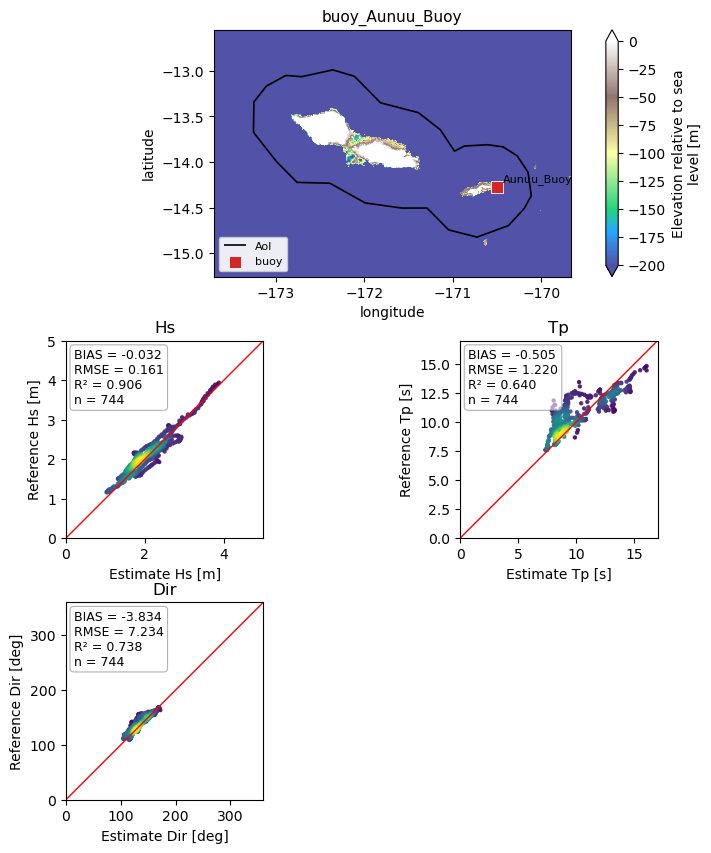

In [7]:
result.plot_all()
plt.show()